# Lab 8: Generative Models (VAE, GAN, Toy Diffusion)
**Course:** Advanced Methods of Artificial Intelligence (AMAI)

This notebook is designed for **Google Colab (≈12 GB RAM)**.

## Learning objectives
- Implement and train a **VAE** on MNIST (stable baseline)
- Implement and train a **DCGAN** on MNIST (training dynamics)
- Implement a **toy diffusion** model on 2D points (noise prediction and reverse sampling)
- Produce samples and interpret qualitative results

> **Runtime guidance:** Keep defaults small. Increase epochs/steps gradually.


In [1]:
# --- Setup (Colab) ---
# If needed:
# !pip -q install -U tensorflow

import os, math, time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU available:', bool(tf.config.list_physical_devices('GPU')))


TensorFlow: 2.21.0
GPU available: False


In [2]:
def show_image_grid(images, n=4, title=None):
    images = np.array(images)
    if images.ndim == 3:
        images = images[..., None]
    images = images[: n*n]
    plt.figure(figsize=(n*2, n*2))
    for i in range(n*n):
        ax = plt.subplot(n, n, i+1)
        ax.imshow(images[i].squeeze(), cmap='gray')
        ax.axis('off')
    if title:
        plt.suptitle(title)
    plt.show()


## 1) Data: MNIST (subset for speed)
- We use a reduced training set to keep runtime and RAM within limits.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step
Train: (20000, 28, 28, 1) Test: (5000, 28, 28, 1)


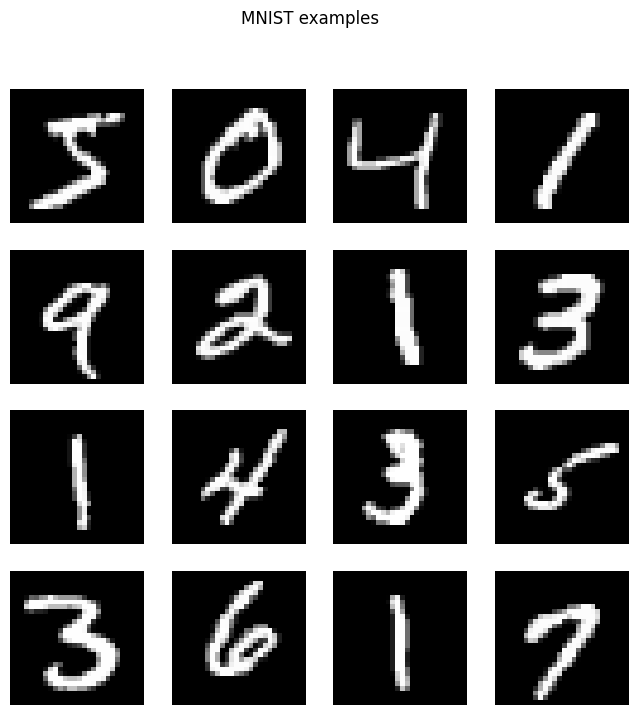

In [3]:
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

x_train = (x_train.astype('float32') / 255.0)[..., None]
x_test  = (x_test.astype('float32') / 255.0)[..., None]

N_TRAIN = 20000
N_TEST  = 5000
x_train = x_train[:N_TRAIN]
x_test  = x_test[:N_TEST]

print('Train:', x_train.shape, 'Test:', x_test.shape)
show_image_grid(x_train[:16], n=4, title='MNIST examples')


# 2) Variational Autoencoder (VAE)
A VAE optimizes:
- **Reconstruction loss** (data fidelity)
- **KL divergence** (latent regularization toward a prior)

### Exercises
- Change `LATENT_DIM` (2, 8, 32)
- Change `BETA` (0.5, 2.0) for a **β-VAE** trade-off


In [4]:
LATENT_DIM = 16   # TODO: 2, 8, 32
BETA = 1.0        # TODO: 0.5, 2.0

# Encoder
enc_in = keras.Input(shape=(28, 28, 1))
h = layers.Conv2D(32, 3, strides=2, padding='same', activation='relu')(enc_in)
h = layers.Conv2D(64, 3, strides=2, padding='same', activation='relu')(h)
h = layers.Flatten()(h)
h = layers.Dense(128, activation='relu')(h)

z_mean = layers.Dense(LATENT_DIM, name='z_mean')(h)
z_logvar = layers.Dense(LATENT_DIM, name='z_logvar')(h)

def reparameterize(args):
    mu, logvar = args
    eps = tf.random.normal(shape=tf.shape(mu))
    return mu + tf.exp(0.5 * logvar) * eps

z = layers.Lambda(reparameterize, name='z')([z_mean, z_logvar])
encoder = keras.Model(enc_in, [z_mean, z_logvar, z], name='encoder')

# Decoder
dec_in = keras.Input(shape=(LATENT_DIM,))
h = layers.Dense(7*7*64, activation='relu')(dec_in)
h = layers.Reshape((7, 7, 64))(h)
h = layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu')(h)
h = layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(h)
dec_out = layers.Conv2DTranspose(1, 3, padding='same', activation='sigmoid')(h)
decoder = keras.Model(dec_in, dec_out, name='decoder')

class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_tracker = keras.metrics.Mean(name='total_loss')
        self.rec_tracker = keras.metrics.Mean(name='recon_loss')
        self.kl_tracker = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_tracker, self.rec_tracker, self.kl_tracker]

    def call(self, x):
        # Required for validation and inference
        _, _, z = self.encoder(x)
        return self.decoder(z)

    def train_step(self, x):
        if isinstance(x, tuple):
            x = x[0]
        with tf.GradientTape() as tape:
            mu, logvar, z = self.encoder(x, training=True)
            x_hat = self.decoder(z, training=True)

            rec = tf.reduce_mean(tf.reduce_sum(
                keras.losses.binary_crossentropy(x, x_hat), axis=(1, 2)
            ))
            kl = -0.5 * tf.reduce_mean(tf.reduce_sum(
                1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1
            ))
            total = rec + self.beta * kl

        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, x):
        if isinstance(x, tuple):
            x = x[0]

        mu, logvar, z = self.encoder(x, training=False)
        x_hat = self.decoder(z, training=False)

        rec = tf.reduce_mean(tf.reduce_sum(
            keras.losses.binary_crossentropy(x, x_hat), axis=(1, 2)
        ))
        kl = -0.5 * tf.reduce_mean(tf.reduce_sum(
            1 + logvar - tf.square(mu) - tf.exp(logvar), axis=1
        ))
        total = rec + self.beta * kl

        self.total_tracker.update_state(total)
        self.rec_tracker.update_state(rec)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

vae = VAE(encoder, decoder, beta=BETA)
vae.compile(optimizer=keras.optimizers.Adam(1e-3))

vae.fit(x_train, epochs=3, batch_size=128, validation_data=(x_test, x_test), verbose=1)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - kl_loss: 3.9803 - recon_loss: 243.3641 - total_loss: 247.3444 - val_kl_loss: 6.0160 - val_recon_loss: 183.5107 - val_total_loss: 189.5267
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - kl_loss: 9.9094 - recon_loss: 165.3335 - total_loss: 175.2428 - val_kl_loss: 11.2855 - val_recon_loss: 147.2830 - val_total_loss: 158.5685
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - kl_loss: 14.5360 - recon_loss: 131.4129 - total_loss: 145.9489 - val_kl_loss: 17.5510 - val_recon_loss: 113.9470 - val_total_loss: 131.4980


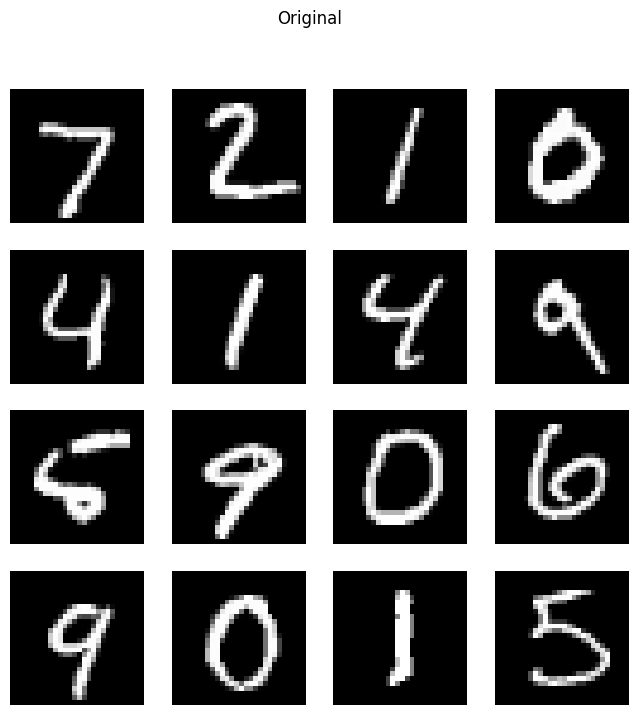

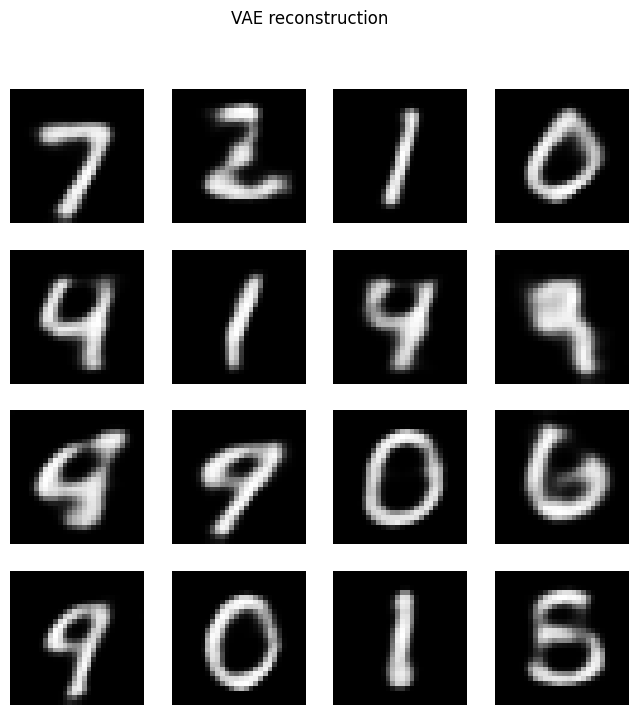

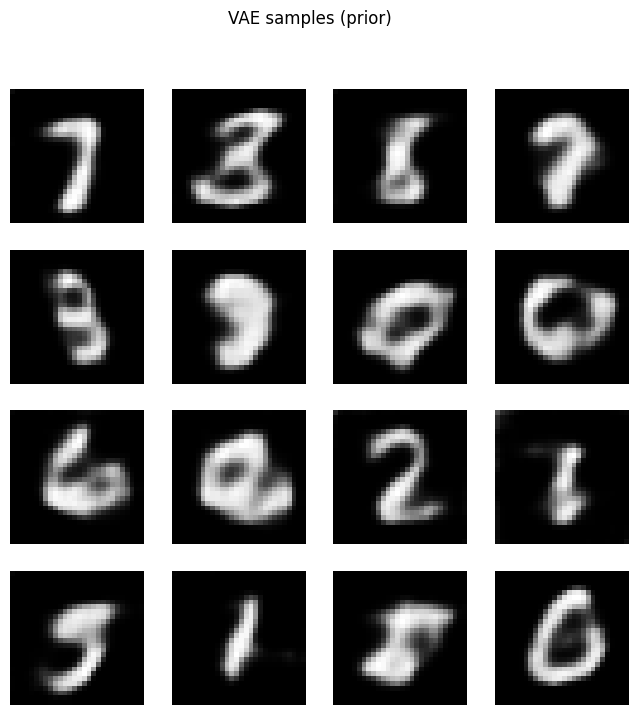

In [5]:
# VAE reconstructions + samples
x_batch = x_test[:16]
_, _, z = encoder.predict(x_batch, verbose=0)
x_recon = decoder.predict(z, verbose=0)

show_image_grid(x_batch, n=4, title='Original')
show_image_grid(x_recon, n=4, title='VAE reconstruction')

z_samples = np.random.randn(16, LATENT_DIM).astype('float32')
x_gen = decoder.predict(z_samples, verbose=0)
show_image_grid(x_gen, n=4, title='VAE samples (prior)')


# 3) GAN (DCGAN on MNIST)
GAN training illustrates **non-convex game dynamics** and potential instability.

### Exercises
- Increase `STEPS` gradually (300 → 1000)
- Try label smoothing (real label = 0.9)
- Adjust learning rates


step   50 | D loss=0.278 | G loss=2.543
step  100 | D loss=0.764 | G loss=1.121
step  150 | D loss=0.901 | G loss=0.931
Time (s): 16.94


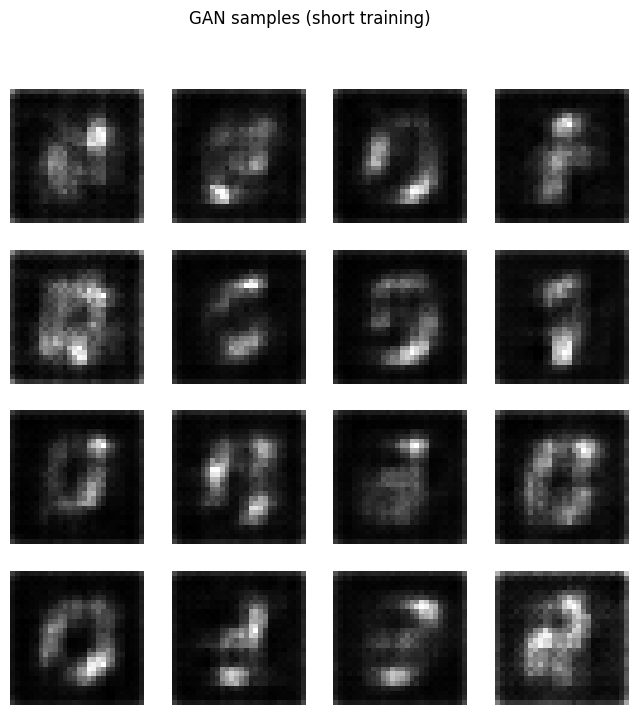

In [6]:
BATCH_SIZE = 128
NOISE_DIM = 100
STEPS = 300   # TODO: 1000

ds = tf.data.Dataset.from_tensor_slices(x_train)
ds = ds.shuffle(5000, seed=SEED).batch(BATCH_SIZE, drop_remainder=True)

def make_generator():
    return keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7*7*128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(64, 4, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2DTranspose(32, 4, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Conv2D(1, 3, padding='same', activation='sigmoid')
    ], name='G')

def make_discriminator():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1)  # logits
    ], name='D')

G = make_generator()
D = make_discriminator()

bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)

def d_loss(real_logits, fake_logits):
    # TODO: label smoothing -> tf.ones_like(real_logits) * 0.9
    return bce(tf.ones_like(real_logits), real_logits) + bce(tf.zeros_like(fake_logits), fake_logits)

def g_loss(fake_logits):
    return bce(tf.ones_like(fake_logits), fake_logits)

@tf.function
def train_step(real_batch):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
    with tf.GradientTape() as d_tape, tf.GradientTape() as g_tape:
        fake = G(noise, training=True)
        real_logits = D(real_batch, training=True)
        fake_logits = D(fake, training=True)
        dl = d_loss(real_logits, fake_logits)
        gl = g_loss(fake_logits)
    d_grads = d_tape.gradient(dl, D.trainable_variables)
    g_grads = g_tape.gradient(gl, G.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, D.trainable_variables))
    g_opt.apply_gradients(zip(g_grads, G.trainable_variables))
    return dl, gl

t0 = time.time()
for step, real_batch in enumerate(ds.take(STEPS), start=1):
    dl, gl = train_step(real_batch)
    if step % 50 == 0:
        print(f'step {step:4d} | D loss={dl.numpy():.3f} | G loss={gl.numpy():.3f}')

print('Time (s):', round(time.time() - t0, 2))

noise = tf.random.normal([16, NOISE_DIM])
samples = G(noise, training=False).numpy()
show_image_grid(samples, n=4, title='GAN samples (short training)')


# 4) Toy diffusion on 2D points (Two Moons)
We learn a network that predicts the noise ε from (x_t, t). Then we run a simplified reverse process.

This is intentionally **educational** and computationally light.


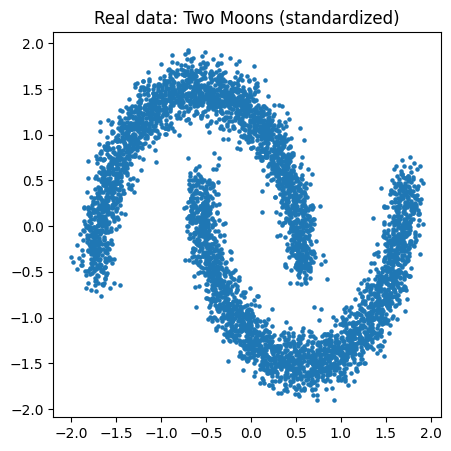

epoch  2 | loss=0.6247
epoch  4 | loss=0.6328
epoch  6 | loss=0.5793
epoch  8 | loss=0.5842
epoch 10 | loss=0.5751


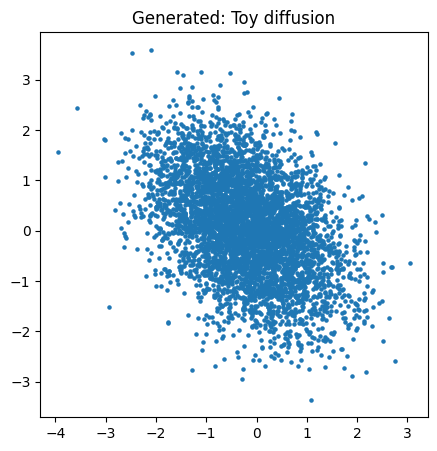

In [7]:
from sklearn.datasets import make_moons

X, _ = make_moons(n_samples=5000, noise=0.08, random_state=SEED)
X = X.astype('float32')
X = (X - X.mean(axis=0)) / X.std(axis=0)

plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], s=5)
plt.title('Real data: Two Moons (standardized)')
plt.show()

T = 200
betas = np.linspace(1e-4, 0.02, T).astype('float32')
alphas = 1.0 - betas
alphas_bar = np.cumprod(alphas).astype('float32')

betas_tf = tf.constant(betas)
alphas_tf = tf.constant(alphas)
alphas_bar_tf = tf.constant(alphas_bar)

def q_sample(x0, t, noise):
    a_bar = tf.gather(alphas_bar_tf, t)[:, None]
    return tf.sqrt(a_bar) * x0 + tf.sqrt(1.0 - a_bar) * noise

def time_embed(t, dim=32):
    t = tf.cast(t, tf.float32)[:, None]
    half = dim // 2
    freqs = tf.exp(-math.log(10000.0) * tf.range(half, dtype=tf.float32) / (half - 1))
    args = t * freqs[None, :]
    return tf.concat([tf.sin(args), tf.cos(args)], axis=1)

# ε_θ(x_t, t)
x_in = keras.Input(shape=(2,))
t_in = keras.Input(shape=(), dtype=tf.int32)
t_emb = layers.Lambda(lambda tt: time_embed(tt, 32))(t_in)
h = layers.Concatenate()([x_in, t_emb])
h = layers.Dense(128, activation='swish')(h)
h = layers.Dense(128, activation='swish')(h)
eps_out = layers.Dense(2)(h)
eps_model = keras.Model([x_in, t_in], eps_out)

opt = keras.optimizers.Adam(1e-3)
X_tf = tf.constant(X)

@tf.function
def diff_train_step(x0):
    B = tf.shape(x0)[0]
    t = tf.random.uniform((B,), 0, T, dtype=tf.int32)
    noise = tf.random.normal((B, 2))
    x_t = q_sample(x0, t, noise)
    with tf.GradientTape() as tape:
        pred = eps_model([x_t, t], training=True)
        loss = tf.reduce_mean(tf.square(pred - noise))
    grads = tape.gradient(loss, eps_model.trainable_variables)
    opt.apply_gradients(zip(grads, eps_model.trainable_variables))
    return loss

ds2 = tf.data.Dataset.from_tensor_slices(X_tf).shuffle(5000, seed=SEED).batch(256)
for epoch in range(1, 11):
    ls = []
    for b in ds2:
        ls.append(diff_train_step(b).numpy())
    if epoch % 2 == 0:
        print(f'epoch {epoch:2d} | loss={np.mean(ls):.4f}')

def p_sample(x_t, t):
    beta_t = tf.gather(betas_tf, t)
    alpha_t = tf.gather(alphas_tf, t)
    a_bar_t = tf.gather(alphas_bar_tf, t)
    eps = eps_model([x_t, t], training=False)
    mean = (1.0 / tf.sqrt(alpha_t)[:, None]) * (x_t - (beta_t / tf.sqrt(1.0 - a_bar_t))[:, None] * eps)
    z = tf.random.normal(tf.shape(x_t))
    sigma = tf.sqrt(beta_t)[:, None]
    return tf.where((t[:, None] > 0), mean + sigma * z, mean)

def sample(n=5000):
    x = tf.random.normal((n, 2))
    for t_int in reversed(range(T)):
        t = tf.fill((n,), t_int)
        x = p_sample(x, t)
    return x.numpy()

X_gen = sample(5000)
plt.figure(figsize=(5,5))
plt.scatter(X_gen[:,0], X_gen[:,1], s=5)
plt.title('Generated: Toy diffusion')
plt.show()


# 5) Reflection questions (short answers)
1. Under short training, which model (VAE vs GAN) appears more stable? Provide a technical reason.
2. In diffusion, what does ε_θ(x_t, t) represent, and why does learning it enable sampling?
3. Identify one failure mode for GANs and one mitigation (e.g., architectural or optimization change).
4. Propose one responsible-deployment control (documentation, filtering, human review, etc.).
